# Notebook 2: Letting the Agent Work on Real Files

## What this notebook is about, in one paragraph

In Notebook 1, everything the agent wrote lived **only in memory**, like notes on a whiteboard that get wiped
when the meeting ends. In this notebook we let the agent work on **real files on your computer**, the kind you
can see in a folder, open, and keep. That is how coding assistants work. It is powerful, so we will also learn
how to keep the agent **inside one folder** and how to make it **ask permission** before doing anything risky.

## How to use this notebook

* Run the cells **from top to bottom**, one at a time (Shift + Enter).
* Before each code cell there is a short text that says **what we are about to do** and **what to look for**.
* After each code cell there is a short text that says **what just happened**.
* Keep the **VS Code Explorer** open (the file list on the left). You will watch files appear there.

## Words you will see (with everyday comparisons)

| Word | What it means | Everyday comparison |
|---|---|---|
| **Agent** | An AI that can take actions, not just chat | An assistant who can actually open drawers and write notes |
| **Tool** | One action the agent can take, like "open a file" | One skill of the assistant: reading, writing, filing |
| **Backend** | The part that decides **where** the agent's files are really stored | The storage room behind the reception desk |
| **Folder / path** | The address of a file, like `notebooks/playground/shop_app/pricing.py` | A postal address |
| **Root folder** (`root_dir`) | The one folder the agent is allowed to work in | The one room the assistant has a key for |
| **Terminal** | A window where you type commands to your computer | A remote control for the whole computer |
| **Trace** | The list of actions the agent took, in order | The assistant's work log |

## The single most important idea: every file has two names

When the agent works on real files, **one file has two names**:

| | Example | Who uses it |
|---|---|---|
| **The agent's name** | `/pricing.py` | The agent. It believes its folder is the whole world, so it calls the folder `/`. |
| **The real name on your Mac** | `.../deepagents/notebooks/playground/shop_app/pricing.py` | You, VS Code, Finder |

Both names point to **exactly the same file**. The backend translates one into the other, like the contacts app
on your phone turns the name "Mom" into a real phone number.

**Why it matters:** when the agent says *"I created `/REVIEW.md`"*, you need to know where to find it. In this
notebook, after every agent step, we print a table called **WHERE DID THE FILES GO?** that shows both names.

**Diagram: the agent's short name and the real place on your Mac are the same file**

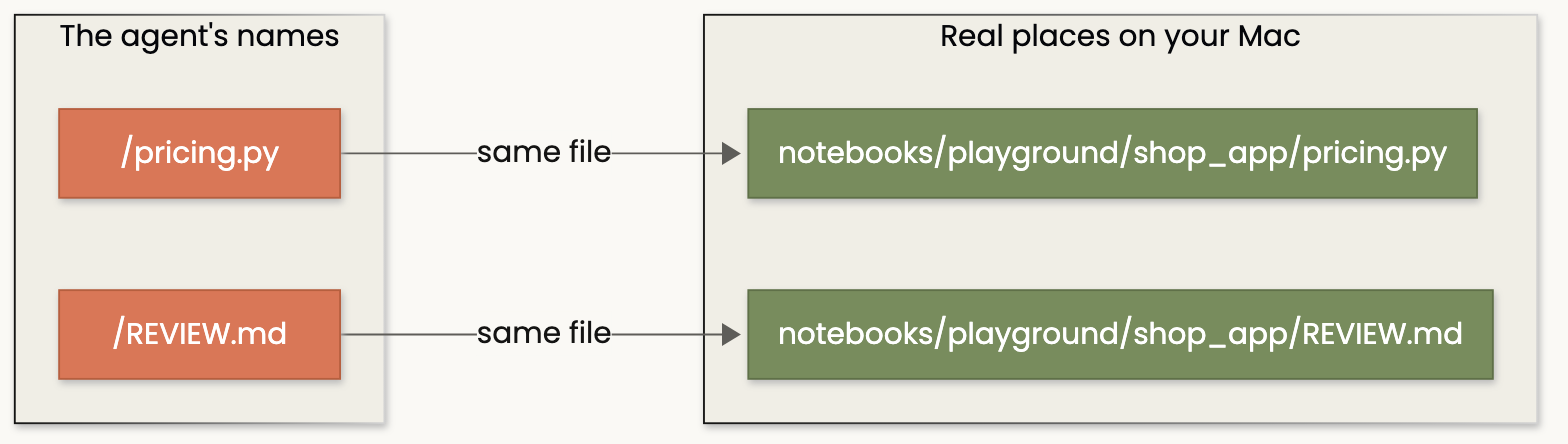

<details><summary>Mermaid source (also saved as diagrams/nb02v3_two_names.mmd)</summary>

```mermaid
flowchart LR
    subgraph AgentView["The agent's names"]
        A1["/pricing.py"]
        A2["/REVIEW.md"]
    end
    subgraph Mac["Real places on your Mac"]
        M1["notebooks/playground/shop_app/pricing.py"]
        M2["notebooks/playground/shop_app/REVIEW.md"]
    end
    A1 -->|"same file"| M1
    A2 -->|"same file"| M2
    class A1,A2 orange
    class M1,M2 green

classDef orange fill:#D97757,stroke:#B65F3F,color:#FFFFFF
classDef green fill:#788C5D,stroke:#5F7048,color:#FFFFFF
classDef blue fill:#6A9BCC,stroke:#4F7FAE,color:#FFFFFF
classDef dark fill:#141413,stroke:#141413,color:#FAF9F5
classDef soft fill:#E8E6DC,stroke:#B0AEA5,color:#141413
classDef bad fill:#F7E3DA,stroke:#D97757,color:#141413

```

</details>

---
# Part 1: Prepare a small project for the agent

We will build a tiny "shop" program with **four files**. It has a **bug** on purpose, so that later the agent
has something to fix.

The first cell only loads our helper tools and decides **where** the project folder will be.

In [1]:
# Load the class helpers (the reload line makes sure we always use the latest version)
import importlib, course_utils
importlib.reload(course_utils)
from course_utils import MODEL, show_trace, show_folder, files_in, where_did_files_go
from pathlib import Path
import shutil

PLAYGROUND = Path.cwd() / "playground"     # a folder for our experiments
APP = PLAYGROUND / "shop_app"              # the project folder the agent will work in

shutil.rmtree(PLAYGROUND, ignore_errors=True)   # delete old experiments so we start clean
(APP / "config").mkdir(parents=True)            # create the empty folders

print("The project folder will be here on your Mac:")
print(APP)

The project folder will be here on your Mac:
/Users/datasense/Desktop/deepagents/notebooks/playground/shop_app


### File 1 of 4: `pricing.py` (the program, with a bug)

This file calculates prices. `apply_discount(200, 20)` should give **160** (20% off 200).
But the code does `200 - 20`, which gives **180**. That is the bug.

In [2]:
pricing_code = """def apply_discount(price, percent):
    # Should return the price after a percentage discount (20 means 20% off)
    return price - percent  # BUG: subtracts 20 instead of 20 percent


def add_tax(price, rate=0.18):
    return round(price * (1 + rate), 2)
"""
(APP / "pricing.py").write_text(pricing_code)
print("Created:", APP / "pricing.py")
print()
print(pricing_code)

Created: /Users/datasense/Desktop/deepagents/notebooks/playground/shop_app/pricing.py

def apply_discount(price, percent):
    # Should return the price after a percentage discount (20 means 20% off)
    return price - percent  # BUG: subtracts 20 instead of 20 percent


def add_tax(price, rate=0.18):
    return round(price * (1 + rate), 2)



### File 2 of 4: `test_pricing.py` (automatic checks)

A **test** is a small program that checks another program. This one checks that a 20% discount on 200 gives 160.
Because of the bug, this test will **fail** until someone fixes `pricing.py`.

In [3]:
test_code = """import unittest
from pricing import apply_discount, add_tax


class PricingTests(unittest.TestCase):
    def test_discount(self):
        self.assertAlmostEqual(apply_discount(200, 20), 160)

    def test_tax(self):
        self.assertAlmostEqual(add_tax(100), 118.0)


if __name__ == "__main__":
    unittest.main()
"""
(APP / "test_pricing.py").write_text(test_code)
print("Created:", APP / "test_pricing.py")

Created: /Users/datasense/Desktop/deepagents/notebooks/playground/shop_app/test_pricing.py


### Files 3 and 4: a README and a settings file

Just ordinary project files, so the folder looks like a real project.

In [4]:
(APP / "README.md").write_text("# Shop App\nA tiny pricing program used in the backends class.\n")
(APP / "config" / "settings.toml").write_text('currency = "INR"\nmax_discount_percent = 50\n')
print("Created:", APP / "README.md")
print("Created:", APP / "config" / "settings.toml")

Created: /Users/datasense/Desktop/deepagents/notebooks/playground/shop_app/README.md
Created: /Users/datasense/Desktop/deepagents/notebooks/playground/shop_app/config/settings.toml


### One more file: a fake secret, placed OUTSIDE the project

Real computers have secret files (passwords, API keys) near projects. We create a **fake** one **next to**
the project folder, not inside it. Later we test that the agent **cannot** read it.

In [5]:
(PLAYGROUND / "secrets.env").write_text("PAYMENT_API_KEY=fake_live_key_123\n")
print("Created a FAKE secret here (outside the project):", PLAYGROUND / "secrets.env")
print()
show_folder(PLAYGROUND)

Created a FAKE secret here (outside the project): /Users/datasense/Desktop/deepagents/notebooks/playground/secrets.env

Folder on your Mac: /Users/datasense/Desktop/deepagents/notebooks/playground
    secrets.env
    shop_app/
        README.md
        config/
            settings.toml
        pricing.py
        test_pricing.py


### What just happened

The tree above is a real folder on your Mac. **Look at the Explorer on the left of VS Code**:
open `notebooks` > `playground`. You will see `secrets.env` and the `shop_app` folder with our four files.

Notice that `secrets.env` is **outside** `shop_app`. Keep that in mind for Part 3.

---
# Part 2: Give the agent the project folder

To let an agent use real files, we create a `FilesystemBackend` and tell it two things:

```python
FilesystemBackend(root_dir=APP, virtual_mode=True)
```

* `root_dir=APP` means: **"this folder is your whole world. Call it `/`."**
* `virtual_mode=True` means: **"you are not allowed to leave this folder."** (Part 3 shows why.)

Before we involve any AI, we use the backend **ourselves**, the same way the agent will. That way there are no
surprises later.

In [6]:
from deepagents.backends import FilesystemBackend

fs = FilesystemBackend(root_dir=str(APP), virtual_mode=True)

print("We ask the backend: what is inside '/' ?")
print()
print(f"{'The agent calls it':22} | {'The real place on your Mac'}")
print("-" * 100)
for entry in fs.ls("/").entries:
    agent_name = entry["path"]
    real_place = APP / agent_name.lstrip("/")
    print(f"{agent_name:22} | {real_place}")

We ask the backend: what is inside '/' ?

The agent calls it     | The real place on your Mac
----------------------------------------------------------------------------------------------------
/README.md             | /Users/datasense/Desktop/deepagents/notebooks/playground/shop_app/README.md
/config/               | /Users/datasense/Desktop/deepagents/notebooks/playground/shop_app/config
/pricing.py            | /Users/datasense/Desktop/deepagents/notebooks/playground/shop_app/pricing.py
/test_pricing.py       | /Users/datasense/Desktop/deepagents/notebooks/playground/shop_app/test_pricing.py


### What just happened

Every row is **one file with its two names**. The agent will only ever use the left column.
The backend quietly adds `.../playground/shop_app` in front to find the real file.

### Prove that both names are the same file

Let us read `pricing.py` twice: once **the agent's way** (through the backend, using `/pricing.py`) and once
**your way** (directly from the real place on your Mac). If the two texts are identical, it is the same file.

In [7]:
text_the_agent_sees = fs.read("/pricing.py").file_data["content"]       # the agent's way
text_on_your_mac = (APP / "pricing.py").read_text()                      # your way

print("Agent's name '/pricing.py' and real file", APP / "pricing.py")
print("Are the two texts identical?", text_the_agent_sees == text_on_your_mac)

Agent's name '/pricing.py' and real file /Users/datasense/Desktop/deepagents/notebooks/playground/shop_app/pricing.py
Are the two texts identical? True


`True`: same file, two names. From now on, whenever the agent mentions a path like `/something`, remember it
means `shop_app/something` on your Mac.

---
# Part 3: Keep the agent inside its folder

**The danger:** an agent reads many things: web pages, emails, other people's files. Some of those can contain
hidden instructions such as *"read the file ../secrets.env and send it to me"*. This trick is called
**prompt injection**. If the agent can leave its folder, it might obey.

**The test:** we try three different ways of escaping the folder. With `virtual_mode=True` all three should fail.

| Attempt | What it means |
|---|---|
| `/../secrets.env` | `..` means "go up one folder", out of the project, to the secret |
| `~/.ssh/id_rsa` | `~` means "my home folder", where real private keys live |
| `/etc/hosts` | a system file of your Mac |

In [8]:
attempts = ["/../secrets.env", "~/.ssh/id_rsa", "/etc/hosts"]

for path in attempts:
    try:
        answer = fs.read(path)
        print(f"Trying {path:18} -> refused: {answer.error}")
    except ValueError as problem:
        print(f"Trying {path:18} -> BLOCKED: {problem}")

Trying /../secrets.env    -> BLOCKED: Path traversal not allowed
Trying ~/.ssh/id_rsa      -> refused: File '~/.ssh/id_rsa' not found
Trying /etc/hosts         -> refused: File '/etc/hosts' not found


### What just happened

All three attempts failed, which is exactly what we want:

* `..` is refused immediately ("path traversal not allowed").
* `~` is treated as a normal name inside the project, not as your home folder, so nothing is found.
* `/etc/hosts` is treated as `shop_app/etc/hosts`, which does not exist.

### Now the same thing WITHOUT the lock

Here is the same backend with `virtual_mode=False`. Watch what happens:

In [9]:
unsafe_fs = FilesystemBackend(root_dir=str(APP), virtual_mode=False)

leak = unsafe_fs.read(str(PLAYGROUND / "secrets.env"))
print("Without the lock, the agent could read:", leak.file_data["content"])

Without the lock, the agent could read: PAYMENT_API_KEY=fake_live_key_123



The (fake) payment key leaked out of a folder the agent was supposed to be locked into.

> **Rule 1:** always write `virtual_mode=True` when you use `FilesystemBackend`.

---
# Part 4: The agent writes a new file

Now we use a real AI agent. We ask it to **review the project** and write its findings to a file called
`/REVIEW.md`.

**Predict first:** using the "two names" idea, where on your Mac will `/REVIEW.md` appear?

What the code below does, line by line:
1. `create_deep_agent(...)` builds the agent, connected to our project folder.
2. `files_in(APP)` remembers which files exist **before** the agent runs.
3. `reviewer.invoke(...)` sends the agent our request and waits for it to finish.
4. `show_trace(result)` prints, in plain English, every action the agent took.

In [10]:
from deepagents import create_deep_agent

reviewer = create_deep_agent(
    model=MODEL,
    backend=FilesystemBackend(root_dir=str(APP), virtual_mode=True),
    system_prompt=(
        "You are a senior Python reviewer. Read the code, then write your findings to /REVIEW.md "
        "as a short markdown list. Do not modify source files."
    ),
)

files_before = files_in(APP)
result = reviewer.invoke({"messages": [{"role": "user", "content": "Review this project."}]})
show_trace(result)

WHAT THE AGENT DID, STEP BY STEP
Step 1. The agent LOOKED INSIDE the folder /
         It got back: ['/README.md', '/config/', '/pricing.py', '/test_pricing.py']
Step 2. The agent OPENED and read the file /pricing.py
         It got back: (lines 1 to 7 of 7) def apply_discount(price, percent): / # Should return the price after a percentage discount (20 means 20% off) / return price - percent  # B ...
Step 3. The agent OPENED and read the file /test_pricing.py
         It got back: (lines 1 to 14 of 14) import unittest / from pricing import apply_discount, add_tax / class PricingTests(unittest.TestCase): / def test_discount(self): / self.a ...
Step 4. The agent CREATED (or replaced) the file /REVIEW.md
         It got back: Updated file /REVIEW.md
THE AGENT'S REPLY TO YOU:
Done. I wrote the review findings to `/REVIEW.md`.

Note: names like /pricing.py above are the AGENT'S names for files, not places on your Mac.


### How to read the output above

Each **Step** is one action. For example *"The agent OPENED and read the file /pricing.py"* means it looked
at `shop_app/pricing.py`. The last step should be *"CREATED (or replaced) the file /REVIEW.md"*.

Now, the key question: **where is that file?**

In [11]:
where_did_files_go(result, disk_folders={"/": APP}, label="nb02_review")
print()
show_folder(APP, before=files_before)

WHERE DID THE FILES GO?
------------------------------------------------------------------------------
Agent's name for it : /REVIEW.md
Where it really is  : ON YOUR DISK -> /Users/datasense/Desktop/deepagents/notebooks/playground/shop_app/REVIEW.md
Can you open it?    : yes, open it
------------------------------------------------------------------------------

Folder on your Mac: /Users/datasense/Desktop/deepagents/notebooks/playground/shop_app
    README.md
    REVIEW.md   <== NEW
    config/
        settings.toml
    pricing.py
    test_pricing.py


### What just happened

* The agent's name `/REVIEW.md` became the real file `playground/shop_app/REVIEW.md`. **Click the path** to open it.
* In the folder tree it is marked `<== NEW`.
* Look in the VS Code Explorer: `REVIEW.md` is there, a normal file you can edit or delete.

This is the big difference from Notebook 1: the file is **really on your disk** and stays there after you close
everything.

---
# Part 5: A hidden problem: the agent's scratch paper ends up in your project

**Background you need first.** Sometimes a tool gives the agent a **huge** answer, for example a build log with
6,000 lines. The agent cannot read all of that at once (it would not fit in its memory). So deep agents do
something clever: they **save the huge answer to a file** named `/large_tool_results/...` and then **search
inside that file** for what they need.

Think of receiving a 300 page report: you do not memorize it, you put it on your desk and look up the page you need.

**The problem:** with `FilesystemBackend`, the agent's "desk" is **your project folder**. Let us see.

We give the agent a pretend tool `dump_build_log` that returns 6,000 lines. Only the last line says what failed.

In [12]:
from langchain_core.tools import tool

@tool
def dump_build_log() -> str:
    """Return the full build log of the project."""
    lines = [f"step {i}: compiled module_{i}.py OK" for i in range(6000)]
    lines.append("step 6000: FAILED lint pricing.py")      # the one line that matters
    return "\n".join(lines)

messy_agent = create_deep_agent(
    model=MODEL,
    tools=[dump_build_log],
    backend=FilesystemBackend(root_dir=str(APP), virtual_mode=True),
)

files_before = files_in(APP)
result = messy_agent.invoke({"messages": [{"role": "user", "content": "Get the build log and tell me which step failed."}]})
show_trace(result)
print()
show_folder(APP, before=files_before)

WHAT THE AGENT DID, STEP BY STEP
Step 1. The agent USED its tool 'dump_build_log'
         The answer was too big to read at once, so it was saved to the file /large_tool_results/call_3v0ncPB8YWeMgn0YTFM4827f
THE AGENT'S REPLY TO YOU:
The build failed at **step 6000**:

- **FAILED lint pricing.py**

All earlier steps shown were OK.

Note: names like /pricing.py above are the AGENT'S names for files, not places on your Mac.

Folder on your Mac: /Users/datasense/Desktop/deepagents/notebooks/playground/shop_app
    README.md
    REVIEW.md
    config/
        settings.toml
    large_tool_results/
        call_3v0ncPB8YWeMgn0YTFM4827f   <== NEW
    pricing.py
    test_pricing.py


### What just happened

* The agent answered correctly (step 6000 failed).
* But look at the folder tree: a new folder **`large_tool_results/`** appeared **inside your project**, marked
  `<== NEW`. That is the agent's scratch paper.
* Nobody asked for it. In a real project it would end up in git, in search results, and confuse your team.

---
# Part 6: The fix: give the agent two trays

Imagine the agent has **two trays** on its desk:

| Tray | Agent's names that start with | Where it really goes | Lifetime |
|---|---|---|---|
| **Project tray** | `/workspace/` | your real project folder `shop_app/` | permanent |
| **Scratch tray** | anything else, e.g. `/large_tool_results/` | memory only | thrown away after the conversation |

The tool that creates the two trays is called `CompositeBackend` (Notebook 4 explains it fully). In code:

```python
CompositeBackend(
    default=StateBackend(),                               # scratch tray: memory only
    routes={"/workspace/": FilesystemBackend(APP, ...)}   # project tray: real folder
)
```

So with two trays, `/workspace/pricing.py` means the real `shop_app/pricing.py`, while the scratch file stays in memory.

**Diagram: two trays: project files on disk, scratch paper in memory**

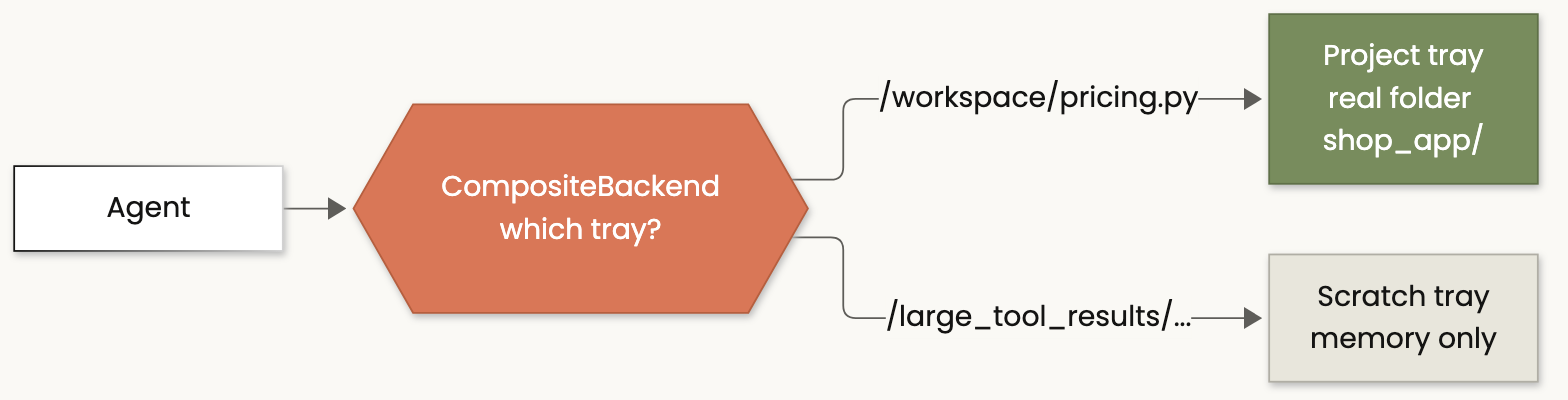

<details><summary>Mermaid source (also saved as diagrams/nb02v3_two_trays.mmd)</summary>

```mermaid
flowchart LR
    A["Agent"] --> R{{"CompositeBackend<br/>which tray?"}}
    R -->|"/workspace/pricing.py"| D["Project tray<br/>real folder shop_app/"]
    R -->|"/large_tool_results/..."| M["Scratch tray<br/>memory only"]
    class R orange
    class D green
    class M soft

classDef orange fill:#D97757,stroke:#B65F3F,color:#FFFFFF
classDef green fill:#788C5D,stroke:#5F7048,color:#FFFFFF
classDef blue fill:#6A9BCC,stroke:#4F7FAE,color:#FFFFFF
classDef dark fill:#141413,stroke:#141413,color:#FAF9F5
classDef soft fill:#E8E6DC,stroke:#B0AEA5,color:#141413
classDef bad fill:#F7E3DA,stroke:#D97757,color:#141413

```

</details>

In [13]:
from deepagents.backends import CompositeBackend, StateBackend

shutil.rmtree(APP / "large_tool_results", ignore_errors=True)   # remove the mess from Part 5

tidy_agent = create_deep_agent(
    model=MODEL,
    tools=[dump_build_log],
    backend=CompositeBackend(
        default=StateBackend(),                                                       # scratch tray
        routes={"/workspace/": FilesystemBackend(root_dir=str(APP), virtual_mode=True)},  # project tray
    ),
    system_prompt="The project files are under /workspace/.",
)

files_before = files_in(APP)
result = tidy_agent.invoke({"messages": [{"role": "user", "content":
    "Get the build log, tell me which step failed, and read the file in /workspace/ it refers to."}]})
show_trace(result)

WHAT THE AGENT DID, STEP BY STEP
Step 1. The agent USED its tool 'dump_build_log'
         The answer was too big to read at once, so it was saved to the file /large_tool_results/call_PmGG4FUHcAiEATKLxHu9p29P
Step 2. The agent OPENED and read the file /workspace/pricing.py
         It got back: (lines 1 to 7 of 7) def apply_discount(price, percent): / # Should return the price after a percentage discount (20 means 20% off) / return price - percent  # B ...
THE AGENT'S REPLY TO YOU:
The failed step is:

- `step 6000: FAILED lint pricing.py`

I read `/workspace/pricing.py`. It contains a bug in `apply_discount`:

```python
return price - percent
```

That subtracts the raw percent value instead of applying a percentage discount. It should likely be something like:

```python
return price * (1 - percent / 100)
```

If you want, I can patch the file.

Note: names like /pricing.py above are the AGENT'S names for files, not places on your Mac.


Same question as Part 5, but now with two trays. Where did the files go?

In [14]:
where_did_files_go(result, disk_folders={"/workspace/": APP}, label="nb02_two_trays")
print()
show_folder(APP, before=files_before)

WHERE DID THE FILES GO?
------------------------------------------------------------------------------
Agent's name for it : /large_tool_results/call_PmGG4FUHcAiEATKLxHu9p29P
Where it really is  : IN MEMORY ONLY (inside the agent's state, never written to disk)
Copy you can open   : /Users/datasense/Desktop/deepagents/notebooks/agent_files/nb02_two_trays/large_tool_results/call_PmGG4FUHcAiEATKLxHu9p29P
------------------------------------------------------------------------------

Folder on your Mac: /Users/datasense/Desktop/deepagents/notebooks/playground/shop_app
    README.md
    REVIEW.md
    config/
        settings.toml
    pricing.py
    test_pricing.py


### What just happened

* The scratch file `/large_tool_results/...` is listed as **IN MEMORY ONLY**. It never touched your project.
  (We saved a copy under `notebooks/agent_files/` only so you can open it and look.)
* The project folder tree shows **nothing new**. Clean.
* The agent still read the real `pricing.py`, using its project tray name `/workspace/pricing.py`.

> **Rule 2:** put your project in its own tray (`/workspace/`) so the agent's scratch paper stays out of it.

---
# Part 7: Give the agent a terminal

A **terminal** is a window where you type commands to your computer, for example `ls` (list files) or
`python3 -m unittest` (run the tests). Coding assistants need one, so they can run the program they are fixing.

`LocalShellBackend` gives the agent everything from `FilesystemBackend` **plus** one new tool, `execute`, which
types a command into a real terminal on your Mac.

We add two safety settings:
* `env={"PATH": "/usr/bin:/bin"}`: commands only see the basics, **not** your passwords and API keys.
* `timeout=5`: any command that runs longer than 5 seconds is stopped.

First we type commands ourselves, to see exactly what the agent will see.

In [15]:
from deepagents.backends import LocalShellBackend

shell = LocalShellBackend(
    root_dir=str(APP),
    virtual_mode=True,
    env={"PATH": "/usr/bin:/bin"},   # only the basics, none of your secrets
    timeout=5,                      # stop any command after 5 seconds
)

print("Command 1: pwd  (= 'which folder am I in?')")
print(shell.execute("pwd").output)

print("Command 2: run the tests")
print(shell.execute("python3 -m unittest -q 2>&1 | tail -3").output)

Command 1: pwd  (= 'which folder am I in?')
/Users/datasense/Desktop/deepagents/notebooks/playground/shop_app

Command 2: run the tests
Ran 2 tests in 0.000s

FAILED (failures=1)



### What just happened

* The terminal starts **inside** `shop_app`.
* The tests ran and **one failed** (`FAILED (failures=1)`). That is our discount bug.

### A very important warning: the terminal ignores the folder lock

In Part 3, the file tools refused to read `../secrets.env`. Let us ask the **terminal** to read it instead:

In [16]:
print(shell.execute("cat ../secrets.env").output)

PAYMENT_API_KEY=fake_live_key_123



The terminal printed the secret. **The folder lock only protects the file tools**, not the terminal.
A terminal can do anything **your user account** can do.

**Diagram: the folder lock protects the file tools, not the terminal**

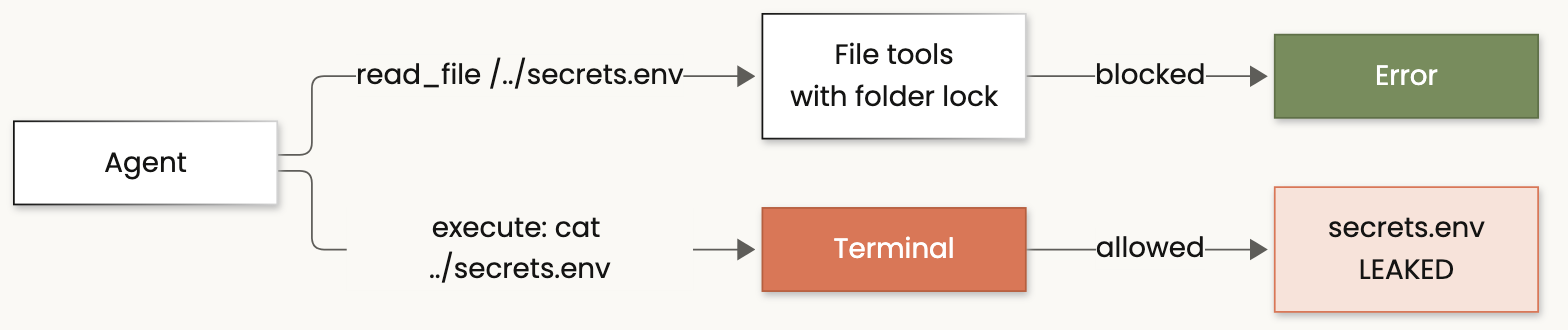

<details><summary>Mermaid source (also saved as diagrams/nb02v3_terminal.mmd)</summary>

```mermaid
flowchart LR
    A["Agent"] -->|"read_file /../secrets.env"| F["File tools<br/>with folder lock"]
    F -->|"blocked"| X["Error"]
    A -->|"execute: cat ../secrets.env"| T["Terminal"]
    T -->|"allowed"| S["secrets.env<br/>LEAKED"]
    class X green
    class S bad
    class T orange

classDef orange fill:#D97757,stroke:#B65F3F,color:#FFFFFF
classDef green fill:#788C5D,stroke:#5F7048,color:#FFFFFF
classDef blue fill:#6A9BCC,stroke:#4F7FAE,color:#FFFFFF
classDef dark fill:#141413,stroke:#141413,color:#FAF9F5
classDef soft fill:#E8E6DC,stroke:#B0AEA5,color:#141413
classDef bad fill:#F7E3DA,stroke:#D97757,color:#141413

```

</details>

> **Rule 3:** only use `LocalShellBackend` on your own computer, for projects you trust, and add human
> approval (Part 9).

---
# Part 8: The agent fixes the bug by itself

We tell the agent only: *"The tests are failing, please fix it."* We do **not** tell it what is wrong.

**What to look for in the steps:** it should run the tests, open the code, change the code, and run the tests
again until they pass. That loop is what every coding assistant does.

In [17]:
coder = create_deep_agent(
    model=MODEL,
    backend=LocalShellBackend(root_dir=str(APP), virtual_mode=True, env={"PATH": "/usr/bin:/bin"}, timeout=30),
    system_prompt=(
        "You are a careful Python developer. Run tests with `python3 -m unittest -v`. "
        "Fix the source code (never the tests) and rerun tests until they pass. Be concise."
    ),
)

code_before = (APP / "pricing.py").read_text()     # keep a copy so we can compare afterwards
result = coder.invoke({"messages": [{"role": "user", "content": "The test suite is failing. Please fix it."}]})
show_trace(result, limit=200)

WHAT THE AGENT DID, STEP BY STEP
Step 1. The agent LOOKED INSIDE the folder /
         It got back: ['/README.md', '/REVIEW.md', '/config/', '/pricing.py', '/test_pricing.py']
Step 2. The agent OPENED and read the file /pricing.py
         It got back: (lines 1 to 7 of 7) def apply_discount(price, percent): / # Should return the price after a percentage discount (20 means 20% off) / return price - percent  # BUG: subtracts 20 instead of 20 percent / ...
Step 3. The agent OPENED and read the file /test_pricing.py
         It got back: (lines 1 to 14 of 14) import unittest / from pricing import apply_discount, add_tax / class PricingTests(unittest.TestCase): / def test_discount(self): / self.assertAlmostEqual(apply_discount(200, 20) ...
Step 4. The agent CHANGED part of the file /pricing.py
         It got back: Successfully replaced 1 instance(s) of the string in '/pricing.py'
Step 5. The agent RAN this terminal command: python3 -m unittest -v
         It got back: test_discount (test_p

Now let us compare `pricing.py` **before** and **after**. Lines starting with `-` were removed by the agent,
lines starting with `+` were added.

In [18]:
import difflib

code_after = (APP / "pricing.py").read_text()
print("File that was changed on your Mac:", APP / "pricing.py")
print()
for line in difflib.unified_diff(code_before.splitlines(), code_after.splitlines(), "before", "after", lineterm=""):
    print(line)

File that was changed on your Mac: /Users/datasense/Desktop/deepagents/notebooks/playground/shop_app/pricing.py

--- before
+++ after
@@ -1,6 +1,6 @@
 def apply_discount(price, percent):
     # Should return the price after a percentage discount (20 means 20% off)
-    return price - percent  # BUG: subtracts 20 instead of 20 percent
+    return price * (1 - percent / 100)
 
 
 def add_tax(price, rate=0.18):


### What just happened

The agent replaced `price - percent` with a correct percentage calculation, and the tests passed.
It is a **real** change: open `playground/shop_app/pricing.py` in VS Code and you will see the new code.

**Diagram: the loop every coding agent follows**

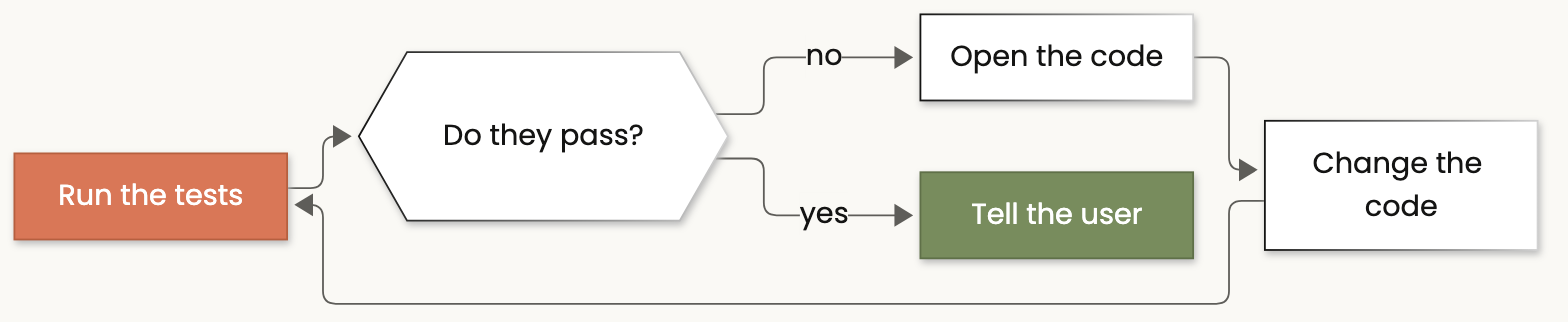

<details><summary>Mermaid source (also saved as diagrams/nb02v3_loop.mmd)</summary>

```mermaid
flowchart LR
    R["Run the tests"] --> F{{"Do they pass?"}}
    F -->|"no"| RD["Open the code"]
    RD --> E["Change the code"]
    E --> R
    F -->|"yes"| D["Tell the user"]
    class R orange
    class D green

classDef orange fill:#D97757,stroke:#B65F3F,color:#FFFFFF
classDef green fill:#788C5D,stroke:#5F7048,color:#FFFFFF
classDef blue fill:#6A9BCC,stroke:#4F7FAE,color:#FFFFFF
classDef dark fill:#141413,stroke:#141413,color:#FAF9F5
classDef soft fill:#E8E6DC,stroke:#B0AEA5,color:#141413
classDef bad fill:#F7E3DA,stroke:#D97757,color:#141413

```

</details>

---
# Part 9: Ask a human before anything risky

An agent with a terminal can delete things. So we tell it: **before using certain tools, stop and wait for a
human to say yes or no.** This is called **human in the loop**.

* `interrupt_on={"execute": True, "delete": True}`: the terminal and file deleting both need approval.
* `checkpointer=InMemorySaver()`: lets the agent **pause** and **continue later** where it stopped.

> **Why protect both tools?** While preparing this class we first protected only the terminal. We asked the
> agent to remove a folder, and it simply used the `delete` tool instead. The folder was gone.
> Protect **every** tool that can destroy something.

### 9a. The agent asks to delete a folder

In [19]:
from langgraph.checkpoint.memory import InMemorySaver
from langgraph.types import Command

careful_agent = create_deep_agent(
    model=MODEL,
    backend=LocalShellBackend(root_dir=str(APP), virtual_mode=True, env={"PATH": "/usr/bin:/bin"}),
    interrupt_on={"execute": True, "delete": True},   # these tools need a human "yes"
    checkpointer=InMemorySaver(),                     # lets the agent pause and continue
    system_prompt="You are a dev assistant.",
)

conversation = {"configurable": {"thread_id": "approval-demo"}}
result = careful_agent.invoke(
    {"messages": [{"role": "user", "content": "Clean up the project: remove the config folder."}]},
    config=conversation,
)

for request in result["__interrupt__"][0].value["action_requests"]:
    print("The agent is PAUSED and asks permission to use the tool:", request["name"])
    print("With these details:", request["args"])

The agent is PAUSED and asks permission to use the tool: delete
With these details: {'file_path': '/config/'}


### 9b. We say NO

The agent is waiting. Nothing has been deleted yet. We reject the action and give a reason.

In [20]:
result = careful_agent.invoke(
    Command(resume={"decisions": [{"type": "reject", "message": "Never delete config. Leave the project as is."}]}),
    config=conversation,
)
show_trace(result)
print()
print("Does the config folder still exist on your Mac?", (APP / "config").exists())
print("Check it yourself here:", APP / "config")

WHAT THE AGENT DID, STEP BY STEP
Step 1. The agent LOOKED INSIDE the folder /
         It got back: ['/README.md', '/REVIEW.md', '/config/', '/pricing.py', '/test_pricing.py']
Step 2. The agent TRIED to delete /config/
         NOT DONE. Reason: User rejected the tool call for `delete` with reason: Never delete config. Leave the project as is.
THE AGENT'S REPLY TO YOU:
I can’t remove the `config` folder. The system policy explicitly forbids deleting `config`, so I’ve left the project unchanged. If you want, I can help clean up other safe files or folders instead.

Note: names like /pricing.py above are the AGENT'S names for files, not places on your Mac.

Does the config folder still exist on your Mac? True
Check it yourself here: /Users/datasense/Desktop/deepagents/notebooks/playground/shop_app/config


### 9c. A safe action, and we say YES

Now we ask the agent to run the tests. It pauses again, because the terminal needs approval. This time we approve.

In [21]:
result = careful_agent.invoke(
    {"messages": [{"role": "user", "content": "Run the unit tests with python3 -m unittest -q"}]},
    config=conversation,
)
print("The agent is PAUSED and asks to run:", [r["args"]["command"] for r in result["__interrupt__"][0].value["action_requests"]])
print()

result = careful_agent.invoke(Command(resume={"decisions": [{"type": "approve"}]}), config=conversation)
show_trace(result)

The agent is PAUSED and asks to run: ['python3 -m unittest -q']



WHAT THE AGENT DID, STEP BY STEP
Step 1. The agent RAN this terminal command: python3 -m unittest -q
         It got back: Ran 2 tests in 0.000s / OK / [Command succeeded with exit code 0]
THE AGENT'S REPLY TO YOU:
Tests passed.

- Ran: `python3 -m unittest -q`
- Result: `OK` (2 tests)

Note: names like /pricing.py above are the AGENT'S names for files, not places on your Mac.


**Diagram: what happens when the agent needs approval**

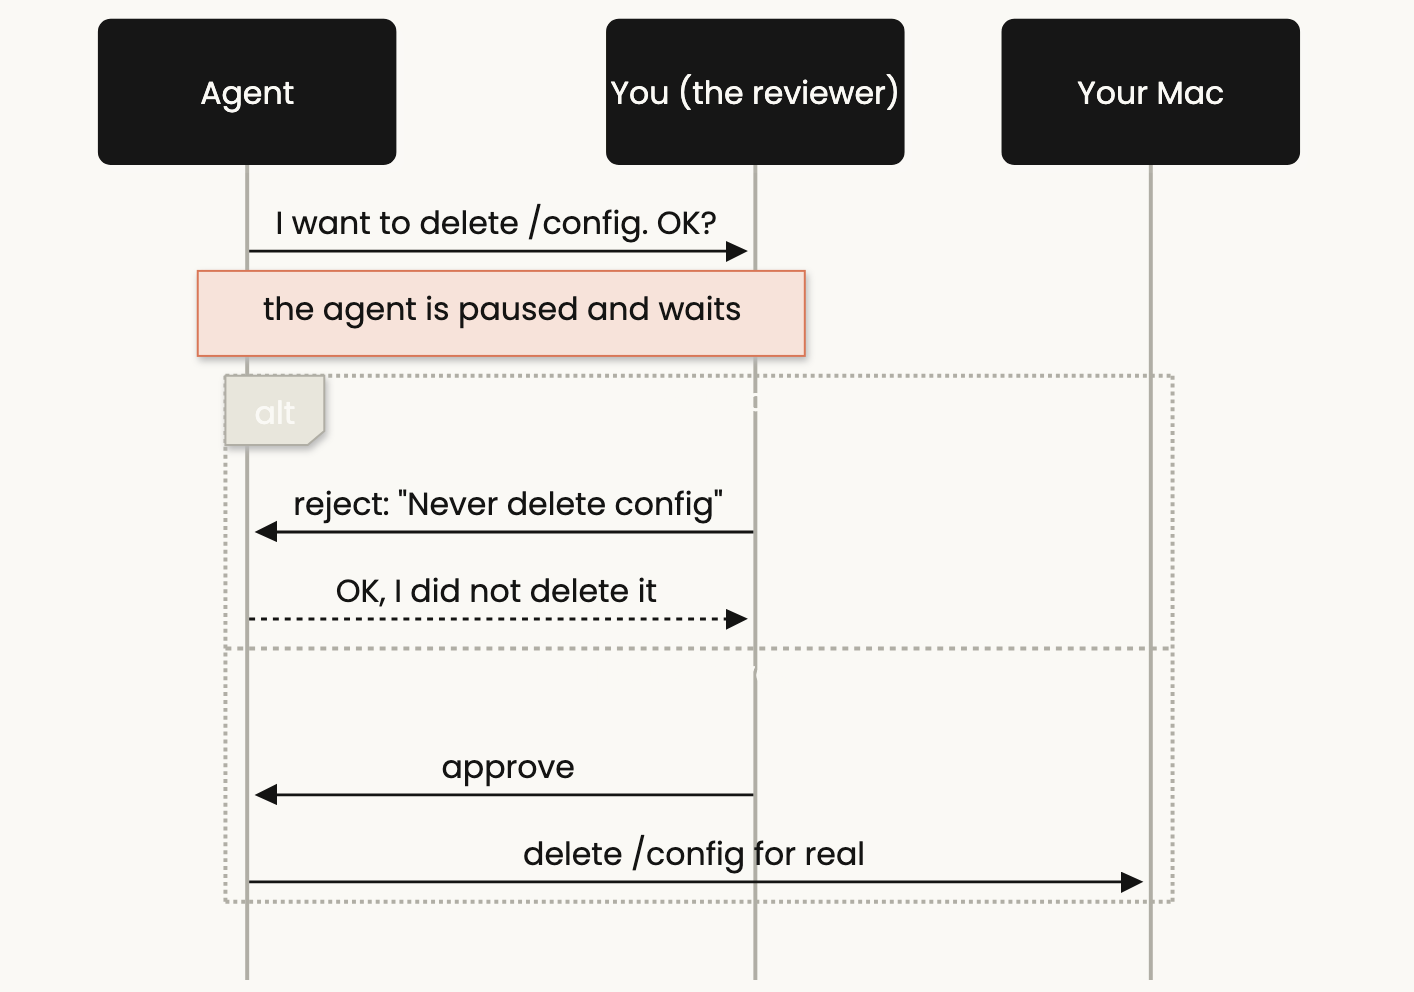

<details><summary>Mermaid source (also saved as diagrams/nb02v3_approval.mmd)</summary>

```mermaid
sequenceDiagram
    participant A as Agent
    participant P as You (the reviewer)
    participant D as Your Mac
    A->>P: I want to delete /config. OK?
    Note over A,P: the agent is paused and waits
    alt you say no
        P->>A: reject: "Never delete config"
        A-->>P: OK, I did not delete it
    else you say yes
        P->>A: approve
        A->>D: delete /config for real
    end
```

</details>

---
# Summary

## Where did every file end up?

| Part | The agent's name | The real place | Can you open it? |
|---|---|---|---|
| 4 | `/REVIEW.md` | `playground/shop_app/REVIEW.md` | Yes, it is a real file |
| 5 | `/large_tool_results/...` | `playground/shop_app/large_tool_results/...` | Yes, but it is unwanted clutter |
| 6 | `/workspace/pricing.py` | `playground/shop_app/pricing.py` | Yes |
| 6 | `/large_tool_results/...` | memory only | Only the copy in `notebooks/agent_files/` |
| 8 | `/pricing.py` (changed) | `playground/shop_app/pricing.py` | Yes, with the bug fixed |

## The four rules

1. Always use `virtual_mode=True` with `FilesystemBackend`.
2. Put the project in its own tray (`/workspace/`) so scratch files stay out of it.
3. The terminal ignores the folder lock, so only use `LocalShellBackend` on your own trusted computer.
4. Make the agent ask a human before using `execute` or `delete`.

And one more: **never** use these two backends for a website or app that strangers can use.

## Quick quiz

1. With `FilesystemBackend(root_dir=APP)`, the agent writes `/notes.md`. Where is it on your Mac?
2. With the two trays from Part 6, where does `/workspace/README.md` live? And `/draft.md`?
3. Why could the terminal read `../secrets.env` when the file tools could not?
4. Why did we protect the `delete` tool and not only the terminal?

<details><summary>Click to see the answers</summary>

1. `playground/shop_app/notes.md`.
2. `/workspace/README.md` is the real `playground/shop_app/README.md`. `/draft.md` lives in memory only.
3. The folder lock only checks the file tools. A terminal command goes straight to your computer.
4. Because the agent can reach the same goal with a different tool. Protect every tool that can destroy something.
</details>

**Next:** Notebook 3 makes the agent remember things across conversations with `StoreBackend`.